## Convert coverage to SNV frequencies 

## 0. General

### 0.1. load Libraries

In [1]:
import os, pandas as pd, numpy as np, json
import statistics as st
from scipy.stats import binom, pearsonr
from scipy.optimize import minimize
from Bio import SeqIO
from Bio.Seq import Seq

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white", font="Arial")
sns.set_context({'font.size': 10.0, 'axes.labelsize': 12, 'axes.titlesize': 14,
                 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
                 'legend.title_fontsize': None, 'axes.linewidth': 0.8, 'grid.linewidth': 0.8,
                 'lines.linewidth': 1.5, 'lines.markersize': 6.0, 'patch.linewidth': 1.0,
                 'xtick.major.width': 0.5, 'ytick.major.width': 0.5, 'xtick.minor.width': 0.3,
                 'ytick.minor.width': 0.3, 'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
                 'xtick.minor.size': 2.0, 'ytick.minor.size': 2.0,})

plt.rcParams['xtick.bottom'] = True
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['font.size'] = 12
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True


### 0.2. General variables

In [3]:
detection_limit = 0.01 #1% 

In [4]:
donors = [1,2,3,4]
replicates = ["A", "B", "C"]
passages = list(range(0, 110, 10))
tech_reps = [1,2 ]
populations = ["1A", "1B", "1C", "2A", "2B", "2C", "3A", "3B", "3C", "4A", "4B", "4C"]

In [5]:
with open('../data/CDS_H3N2.json') as json_file:
    coding_json = json.load(json_file)
segment_nuc_cds = {r.id:r.seq for r in SeqIO.parse('../data/references/stock_consensus_cds.fasta', 'fasta')}

all_bases = ['A', 'T', 'G', 'C', '-', 'N']
transition_mts = ["G>A", "A>G", "C>T", "T>C"]

aapos2codon = {}
nucpos2aapos = {}
for segment, pdict in coding_json.items():
    aapos2codon[segment] = {}
    nucpos2aapos[segment] = {}
    for protein, posdict in pdict.items():
        aapos2codon[segment][protein] = {}
        
        for aapos in np.arange(1, posdict["pro_aa_pos"][-1]+1):
            nucpos = [posdict["nuc_cds_pos"][i] for i, aap in enumerate(posdict["pro_aa_pos"]) if aap == aapos]
            aapos2codon[segment][protein][aapos] = nucpos
    
        nucpos2aapos[segment][protein] = {nucpos:posdict["pro_aa_pos"][i] for i, nucpos in enumerate(posdict["nuc_cds_pos"])}

        

### 0.3 Functions

In [6]:

#determine SNVs above the detection limit
def assess_variant(var_freq, depth, bqt, bet):
    """assess if called variant is a result of a base calling error """
    pe = 10**(-bqt/10)
    pErr = 1 - binom.cdf(var_freq - 1, depth, pe)

    if (np.isnan(pErr)):
        raise Exception(f'pErr = nan; check freq/coverage/q = {var_freq}, {depth}, {bqt}')
    
    if pErr < bet:
        return True
    else:
        return False


def call_snvs(coverage, segment_nuc_cds, min_coverage, bqt, bet):
    coverage = coverage[coverage["coverage"]>= min_coverage]

    snvs = []
    for i, row in coverage.iterrows():
        for b in all_bases[:-2]: #only A, T, G, C 
            s, p, c,  = row["refname"], row["nucpos"], row["coverage"]
            rb = segment_nuc_cds[s][p-1] #base at position in refenence
            if b!= rb: #if there is an actual mutation going on
                if row[b] > 0 and assess_variant(row[b], row["coverage"], bqt, bet):
                    #determine substitution
                    snv = f"{rb}{p}{b}"

                    snvs.append([s, p, c, b, row[b], row[b]/c, snv,])

    snvs = pd.DataFrame.from_records(snvs, columns = ["refname", "nucpos", "coverage", "read_base", "nuc_count", "nuc_freq", "snv",])
    
    return snvs


#### 0.3.1.  Maximum likelihood estimation of binomial proportions of SNV frequencies
**binomial distribution**: $P_{x} = \binom{n}{x} \cdot p^x \cdot (1-p)^{n-x}$
- $P$: binomial probability 
- $x$: number of times for a specific outcome within n trails
- $\binom{n}{x}$: number of combinations
- $p$: probability of success on a single trail
- $(1-p)^{n-x}$: probability of failure on a single trail
- $n$: number of trails

**likelihood fuction**: $ L(p; n, y) =  \binom{n}{y} p^y \cdot (1-p)^{n-y}$

log likelihood is easier to solve, so:  
**log likelihood fuction**: $ln(L) = ln(L(p; n, y)) = ln(\binom{n}{y}) + y \cdot ln(p) + (n - y) \cdot ln(1-p)$


In [7]:
def neg_log_likelihood(p, observations, trials):
        total_log_likelihood = 0
        for i, x in enumerate(observations):
            n = trials[i]
            total_log_likelihood += binom.logpmf(x, n, p)
        return -total_log_likelihood

def estimate_binomial_mean(count, depth):
    # calculate maximum likelihood estimate using Nelder-Mead for noisy measurements
    x0 = st.mean([count[i]/x for i, x in enumerate(depth)]) #initial guess 
    result = minimize(neg_log_likelihood, x0=x0, args=(count, depth), bounds=[(0, 1)], method="Nelder-Mead")
    if not result.success:
        raise Exception(f'optimizer was not successfull')
    p_mle = result.x[0]
    return p_mle


## Load coverage data and call SNVs
pipeline technically already calls SNVs....

### 1. Call Raw SNVS

In [8]:
#calling setting
min_coverage = 500
bet = 0.001
bqt = 30

In [9]:
#coverage dir should exist and contain all nucleotide coverage files
coverage_dir = "../results/nucleotide_coverage"
snv_dir = "../results/snvs"
if not os.path.isdir(snv_dir):
    os.makedirs(snv_dir)

In [10]:
coverage_positions = [] #store coverage per position
#get SNVs per sample 
for f in os.listdir(coverage_dir):
    #infer sample for file name
    sample = "_".join(f.rstrip(".csv").split("_")[-2:])
    coverage = pd.read_csv(os.path.join(coverage_dir, f))
    coverage_positions.extend(coverage["coverage"])

    snv_file = os.path.join(snv_dir, f"snvs_{sample}.csv")
    if not os.path.isfile(snv_file):
        snvs = call_snvs(coverage, segment_nuc_cds, min_coverage, bqt, bet)
        #remove snvs with frequency below the detection limit
        snvs = snvs[snvs["nuc_freq"]>=detection_limit]
        snvs.to_csv(snv_file, index=False)
        


In [11]:
#coverage stats
print ("mean coverage", round (np.mean(coverage_positions)))
print ("median coverage", round (np.median(coverage_positions)))
print ("IQR coverage", round (np.quantile(coverage_positions, 0.25)), round (np.quantile(coverage_positions, 0.75)))
print ("min coverage", round (min(coverage_positions)), round (max(coverage_positions)))

mean coverage 15757
median coverage 12149
IQR coverage 6480 21830
min coverage 172 100037


### 2. Get starting virus SNVS
though clonal starting virus still had some minority variants, we chose to exclude these variants from further analysis

In [12]:
#SNVs need to be present in both !!!!! technical replicates
#first technical replicate
starting_snvs = pd.read_csv(os.path.join(snv_dir, f"snvs_stock_1.csv")).set_index(["refname", "nucpos", "read_base", "snv"])
starting_snvs = starting_snvs.rename(columns={c:f"{c}|tr1" for c in starting_snvs.columns})

#second technical replicate
df = pd.read_csv(os.path.join(snv_dir, f"snvs_stock_2.csv")).set_index(["refname", "nucpos", "read_base", "snv"])
df = df.rename(columns={c:f"{c}|tr2" for c in df.columns})

starting_snvs = pd.concat([starting_snvs, df], axis=1).dropna()

#estimate binomial freq
trc = [c for c in starting_snvs.columns if "|tr" in c]
for i, row in starting_snvs.iterrows():
    #nuc frequency 
    nuc_count = row[[c for c in trc if "nuc_count" in c]].to_list()
    nuc_depth = row[[c for c in trc if c.startswith("coverage")]].to_list()
    starting_snvs.loc[i, "nuc_freq"] = estimate_binomial_mean([int(nc) for nc in nuc_count], [int(nd) for nd in nuc_depth])



### 3. Estimate True SNV frequency from technical replicates

In [13]:
raw_snvs = []
for population in populations:
    for passage in passages[1:]: #skipping p0 i.e. starting virus 
    
        snvs_tr1 = pd.read_csv(os.path.join(snv_dir, f"snvs_P{passage}-{population}_1.csv"), keep_default_na=False, na_values=[""]).set_index(['refname', 'nucpos', 'read_base', "snv"])
        snvs_tr1  = snvs_tr1.rename(columns={c:f"{c}|tr1" for c in snvs_tr1.columns})
        snvs_tr2 = pd.read_csv(os.path.join(snv_dir, f"snvs_P{passage}-{population}_2.csv"), keep_default_na=False, na_values=[""]).set_index(['refname', 'nucpos', 'read_base', "snv"])
        snvs_tr2 = snvs_tr2.rename(columns={c:f"{c}|tr2" for c in snvs_tr2.columns})
    
        #snvs need to be observed in both technical replicates
        snvs = pd.concat([snvs_tr1, snvs_tr2], axis=1).dropna()
        
        #remove snvs observed that are identical to stock snvs
        snvs = snvs[~snvs.index.isin(starting_snvs.index.tolist())]
    
        #using maximum likelihood estimation of the binomial proportions estimate
        for i, row in snvs.iterrows():
            nuc_count = row[[c for c in trc if "nuc_count" in c]].to_list()
            nuc_depth = row[[c for c in trc if c.startswith("coverage")]].to_list()
            snvs.loc[i, "nuc_freq"] = estimate_binomial_mean([int(nc) for nc in nuc_count], [int(nd) for nd in nuc_depth])
            
        snvs.reset_index(inplace=True)
            
        snvs[["population", "passage"]] = population, passage  

        if isinstance(raw_snvs, list):
            raw_snvs = snvs
        else:
            raw_snvs = pd.concat([raw_snvs, snvs], ignore_index=True).fillna(0) 

#remove all observations with estimated frequency below detection_limit
raw_snvs = raw_snvs[raw_snvs["nuc_freq"]>=detection_limit]
raw_snvs = raw_snvs.set_index(['population', 'refname', 'nucpos', 'read_base', 'snv']).sort_index()


In [14]:
#Get effect of each SNV
raw_snv_summary = raw_snvs.copy().reset_index().drop(columns=[c for c in raw_snvs.columns if "|tr" in c]+["passage", "nuc_freq"]).drop_duplicates(ignore_index=True)
raw_snv_summary = raw_snv_summary.sort_values(["population", "refname", "nucpos", "read_base"], ignore_index=True)

for i, (population, refname, nucpos, read_base, snv) in raw_snv_summary.iterrows():
    annotated = False
    for protein, np2aap in nucpos2aapos[refname].items():
        if nucpos in np2aap.keys():
            aapos = np2aap[nucpos]
            codon_positions = aapos2codon[refname][protein][aapos]
            
            original_codon = Seq("".join([segment_nuc_cds[refname][p-1] for p in codon_positions]))
            original_aa = original_codon.translate()
            
            position_in_codon = [i+1 for i,pos in enumerate(codon_positions) if pos==nucpos][0]
            mutated_codon = list(original_codon)
            mutated_codon[position_in_codon-1] = read_base
            mutated_codon = Seq("".join(mutated_codon))
            mutated_aa = mutated_codon.translate()
            aa_mut= f"{original_aa}{aapos}{mutated_aa}"
            ns = True if mutated_aa != original_aa else False
            
            mt = f"{snv[0]}>{snv[-1]}"
            change_type = "Ti" if mt in transition_mts else "Tv"
            
            if not annotated:
                raw_snv_summary.loc[i, ["non_synonymous", "protein", "aapos", "aa_mut", "original_codon", "read_codon", "position_in_codon", "nuc_change", "change_type"]] = [ns, protein, aapos, aa_mut, str(original_codon), str(mutated_codon), position_in_codon, mt, change_type]
                annotated = True
            else:
                raw_snv_summary.loc[len(raw_snv_summary)] = [population, refname, nucpos, read_base, snv,  ns, protein, aapos, aa_mut, str(original_codon), str(mutated_codon), position_in_codon, mt, change_type]
                
raw_snv_summary = raw_snv_summary.sort_values(["population", "refname", "nucpos", "read_base"], ignore_index =True)
raw_snv_summary = raw_snv_summary.set_index(["population", "refname", "nucpos", "snv"]).sort_index()


### 4. Get raw SNV trajectories

In [15]:
raw_trajectories = raw_snvs.copy().reset_index()
raw_trajectories = raw_trajectories.pivot(index=["population", "refname", "nucpos", "snv"], columns="passage", values="nuc_freq").fillna(0)
raw_trajectories.columns.name = None
raw_trajectories[0] = 0
raw_trajectories = raw_trajectories[passages]

In [16]:
raw_trajectories

0         10   20        30        40   \
population refname nucpos snv                                             
1A         1-PB2   312    C312A    0  0.000000  0.0  0.000000  0.011409   
                   358    G358A    0  0.000000  0.0  0.000000  0.034890   
                   574    G574A    0  0.014774  0.0  0.000000  0.000000   
                   639    A639G    0  0.000000  0.0  0.000000  0.000000   
                   867    T867C    0  0.000000  0.0  0.000000  0.000000   
...                              ...       ...  ...       ...       ...   
4C         8-NS    582    C582A    0  0.024820  0.0  0.000000  0.000000   
                   611    G611A    0  0.000000  0.0  0.000000  0.020724   
                   744    A744G    0  0.000000  0.0  0.032148  0.000000   
                   784    A784G    0  0.000000  0.0  0.000000  0.000000   
                   808    G808A    0  0.000000  0.0  0.000000  0.083140   

                                      50        60        70        80   \
population refname nucpos snv                                             
1A         1-PB2   312    C312A  0.000000  0.000000  0.000000  0.000000   
                   358    G358A  0.222882  0.000000  0.000000  0.000000   
                   574    G574A  0.000000  0.000000  0.000000  0.000000   
                   639    A639G  0.054782  0.000000  0.000000  0.000000   
                   867    T867C  0.000000  0.066808  0.481010  0.000000   
...                                   ...       ...       ...       ...   
4C         8-NS    582    C582A  0.000000  0.000000  0.000000  0.000000   
                   611    G611A  0.290097  0.890778  0.999263  0.999647   
                   744    A744G  0.000000  0.000000  0.000000  0.000000   
                   784    A784G  0.000000  0.000000  0.000000  0.000000   
                   808    G808A  0.022465  0.000000  0.000000  0.000000   

                                      90       100  
population refname nucpos snv                       
1A         1-PB2   312    C312A  0.000000  0.00000  
                   358    G358A  0.000000  0.00000  
                   574    G574A  0.000000  0.00000  
                   639    A639G  0.000000  0.00000  
                   867    T867C  0.000000  0.00000  
...                                   ...      ...  
4C         8-NS    582    C582A  0.000000  0.00000  
                   611    G611A  0.999240  0.99955  
                   744    A744G  0.000000  0.00000  
                   784    A784G  0.111442  0.00000  
                   808    G808A  0.000000  0.00000  

[1775 rows x 11 columns]

### 5. Linear Correlation between technical replicates

#### 5.1. Table

In [17]:
#get linear pearson correlation
pcorr = []
for population in populations:
    for passage in passages[1:]:
        df =raw_snvs.loc[population].reset_index()
        df =df[df["passage"]==passage]
        r, p = pearsonr(df["nuc_freq|tr1"], df["nuc_freq|tr2"])
        r = round(r,3)
        p = round(p,2) if p > 0.01 else f'{p:.2e}'
        pcorr.append([population, passage, r, round(r**2,3), p])

pcorr = pd.DataFrame.from_records(pcorr, columns=["population", "passage", "r", "r^2", "p"])
pd.pivot_table(pcorr, index=["population"], columns="passage", values="r^2").fillna(" ")    

passage,10,20,30,40,50,60,70,80,90,100
population,,,,,,,,,,
1A,0.970,1.000,1.000,1.000,0.996,1.000,0.998,1.000,0.982,1.000
1B,0.966,0.998,1.000,1.000,1.000,1.000,1.000,0.998,0.998,1.000
1C,1.000,1.000,1.000,1.000,1.000,1.000,0.996,0.990,1.000,0.998
2A,1.000,1.000,1.000,0.998,1.000,0.998,1.000,1.000,0.998,1.000
2B,1.000,1.000,1.000,0.986,0.980,1.000,0.998,1.000,0.937,0.996
2C,0.980,1.000,0.925,0.998,0.998,0.996,1.000,1.000,0.996,1.000
3A,0.990,0.998,0.998,1.000,1.000,1.000,0.988,1.000,1.000,0.998
3B,1.000,0.998,0.998,0.998,0.996,1.000,0.974,1.000,1.000,0.998
3C,0.994,1.000,1.000,1.000,0.998,0.998,1.000,1.000,1.000,1.000


#### 5.2. Figure 

(-0.0, 1.0)

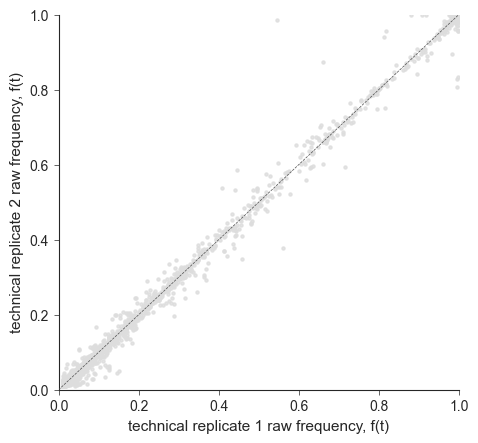

In [18]:
fig, ax = plt.subplots(1, 1, figsize=((5,5)))
plt.subplots_adjust(left=0.1,bottom=0.1, right=0.9, top=0.85, wspace=0.4, hspace=0.6)

ax.plot(ax.get_xlim(), ax.get_ylim(), ls="--", c=".3", lw=0.5, zorder=100)

for population in populations: 
    for passage in passages:
        df = raw_snvs.loc[(population), :].reset_index()
        df = df[df["passage"]==passage]


        ax.scatter(df["nuc_freq|tr1"], df["nuc_freq|tr2"], s=5, zorder=10, alpha=0.8, c="#DDDDDD")

ax.set_xlabel("technical replicate 1 raw frequency, f(t)", size=11)
ax.set_ylabel("technical replicate 2 raw frequency, f(t)", size=11)
ax.spines[['top','right']].set_visible(False)    
ax.set_ylim(-0.0,1.0) 
ax.set_xlim(-0.0,1.0) 
         

### 6. Obtain final dataframes

In [19]:
snv_complete_overview = raw_snvs.copy().reset_index().set_index(["population", "refname", "nucpos", "snv", "passage"]).sort_index()
trajectories = raw_trajectories.copy()
snv_summary = raw_snv_summary.copy()

In [20]:
snv_complete_overview.to_csv("../results/snv_frequencies_complete.csv")
snv_summary.to_csv("../results/snv_summary.csv")
trajectories.to_csv("../results/snv_trajectories.csv")